In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/processed/cleaned_sales_data.csv")
df

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75995,2024-01-30,S005,P0016,Toys,North,233,63,0,29.80,5,Snowy,0,32.23,Winter,0,64
75996,2024-01-30,S005,P0017,Toys,North,137,115,141,42.92,5,Snowy,0,40.73,Winter,0,137
75997,2024-01-30,S005,P0018,Clothing,North,197,44,0,17.81,10,Snowy,0,19.41,Winter,0,68
75998,2024-01-30,S005,P0019,Furniture,North,125,58,0,151.72,0,Snowy,0,143.71,Winter,0,84


In [4]:
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [5]:
df.shape

(76000, 16)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  str    
 1   Store ID            76000 non-null  str    
 2   Product ID          76000 non-null  str    
 3   Category            76000 non-null  str    
 4   Region              76000 non-null  str    
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  str    
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  str    
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  
dtypes: float64(2), 

In [10]:
df["Demand"].describe()

count    76000.000000
mean       104.317158
std         46.964801
min          4.000000
25%         71.000000
50%        100.000000
75%        133.000000
max        430.000000
Name: Demand, dtype: float64

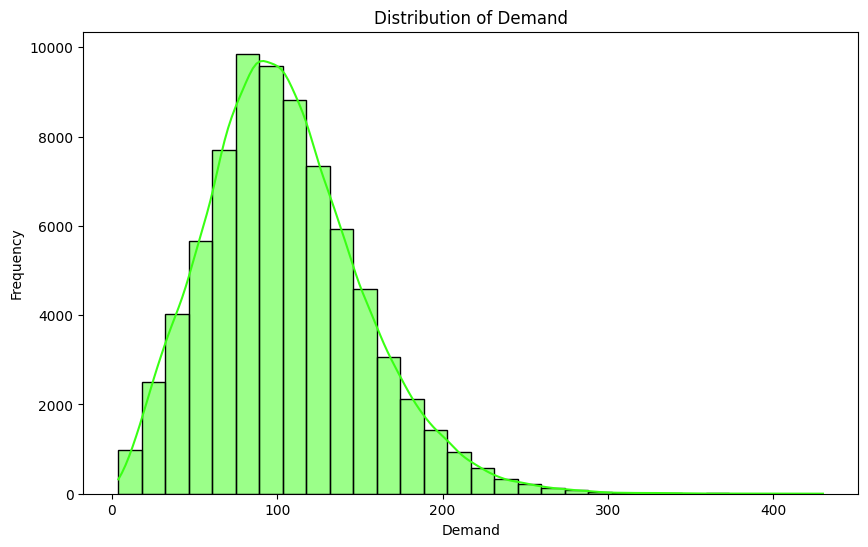

In [21]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Demand",
    bins=30,
    kde=True,color="#39FF14",
    edgecolor="black",
)

plt.title("Distribution of Demand")
plt.xlabel("Demand")
plt.ylabel("Frequency")

plt.show()

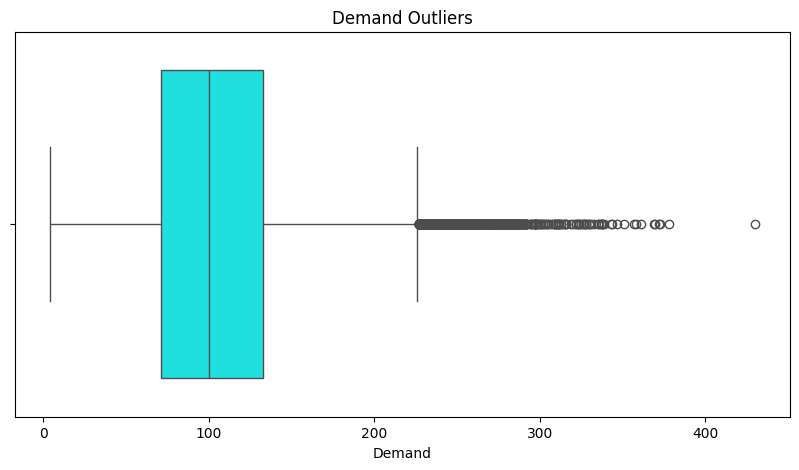

In [22]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["Demand"],color="#00FFFF",
)

plt.title("Demand Outliers")
plt.xlabel("Demand")

plt.show()

In [23]:
df["Price"].describe()

count    76000.000000
mean        67.726028
std         39.377899
min          4.740000
25%         31.997500
50%         64.500000
75%         95.830000
max        228.030000
Name: Price, dtype: float64

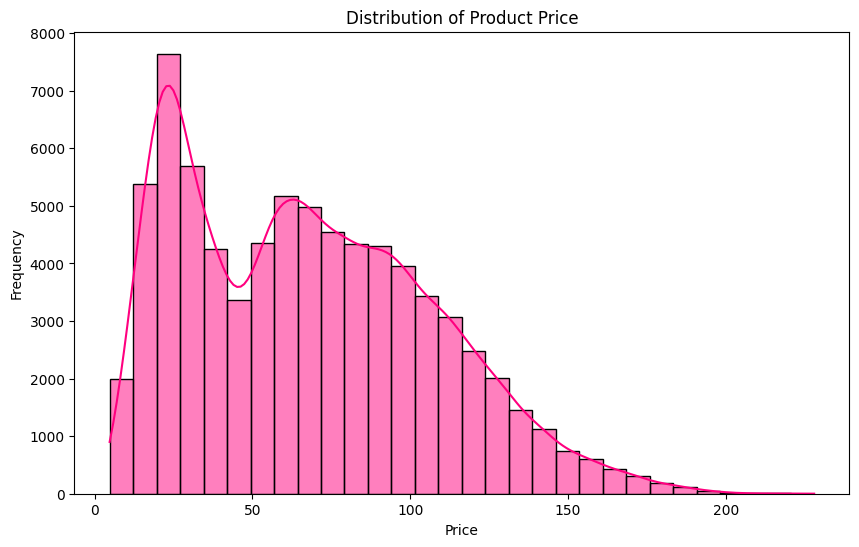

In [25]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Price",
    bins=30,
    kde=True,color="#FF007F"
)

plt.title("Distribution of Product Price")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

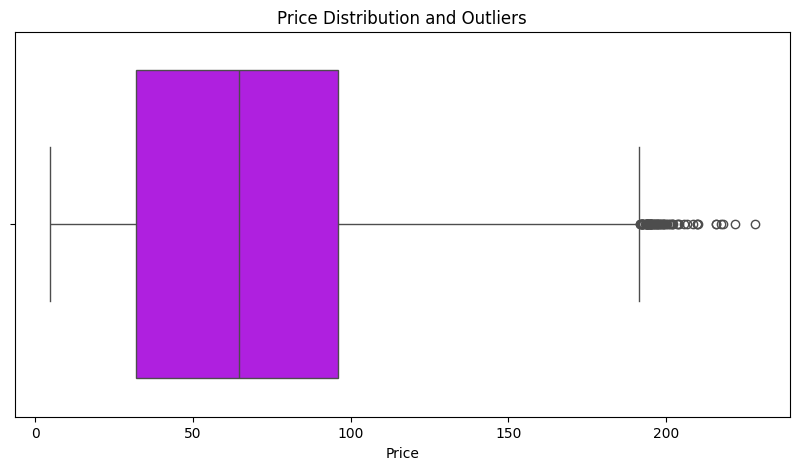

In [28]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["Price"],color="#BF00FF"
)

plt.title("Price Distribution and Outliers")
plt.xlabel("Price")

plt.show()

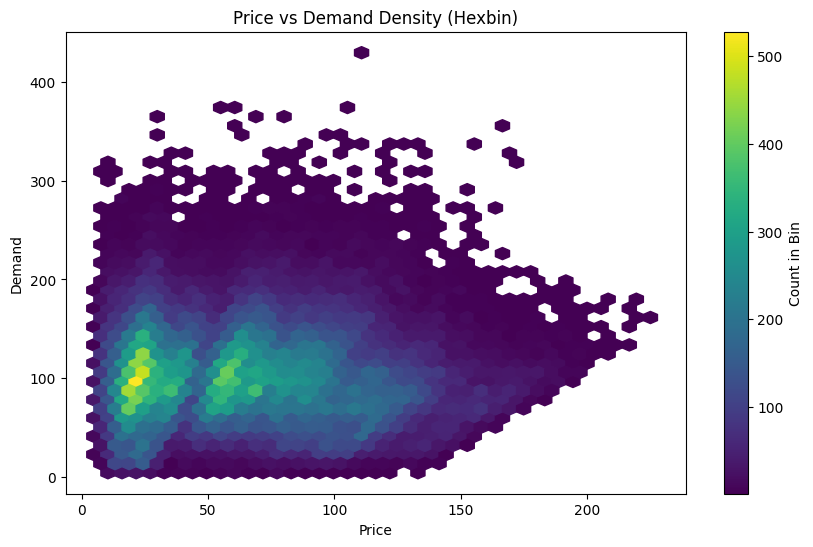

In [33]:
plt.figure(figsize=(10, 6))
plt.hexbin(df["Price"], df["Demand"], gridsize=40, cmap="viridis", mincnt=1)
plt.colorbar(label="Count in Bin")
plt.title("Price vs Demand Density (Hexbin)")
plt.xlabel("Price")
plt.ylabel("Demand")
plt.show()

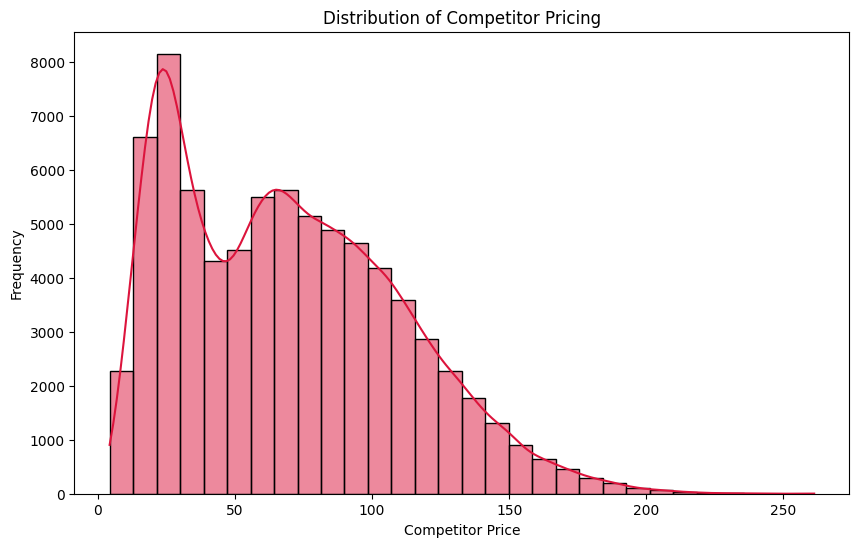

In [36]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Competitor Pricing",
    bins=30,
    kde=True,color="crimson"
)

plt.title("Distribution of Competitor Pricing")
plt.xlabel("Competitor Price")
plt.ylabel("Frequency")

plt.show()

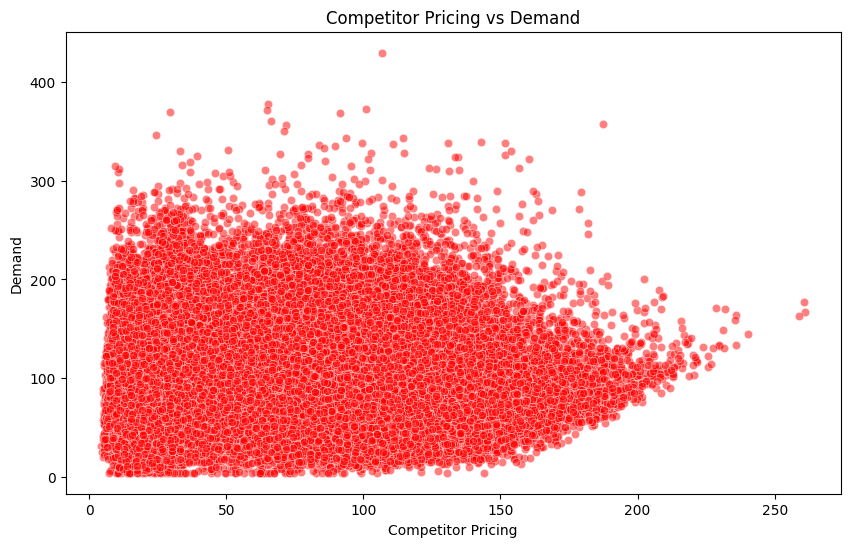

In [37]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Competitor Pricing",
    y="Demand",
    alpha=0.5,color="red"
)

plt.title("Competitor Pricing vs Demand")
plt.xlabel("Competitor Pricing")
plt.ylabel("Demand")

plt.show()

In [38]:
df["Price_Difference"] = (
    df["Price"] - df["Competitor Pricing"]
)

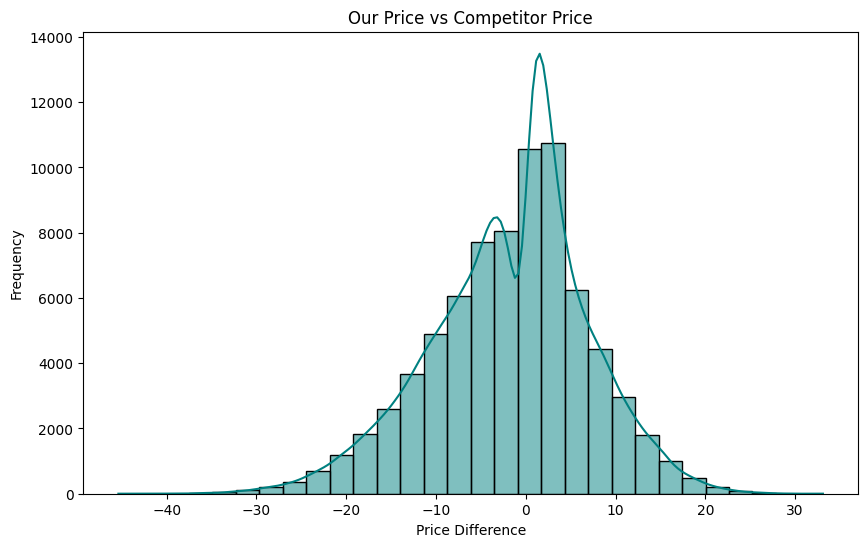

In [39]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Price_Difference",
    bins=30,
    kde=True,color='teal'
)

plt.title("Our Price vs Competitor Price")
plt.xlabel("Price Difference")
plt.ylabel("Frequency")

plt.show()

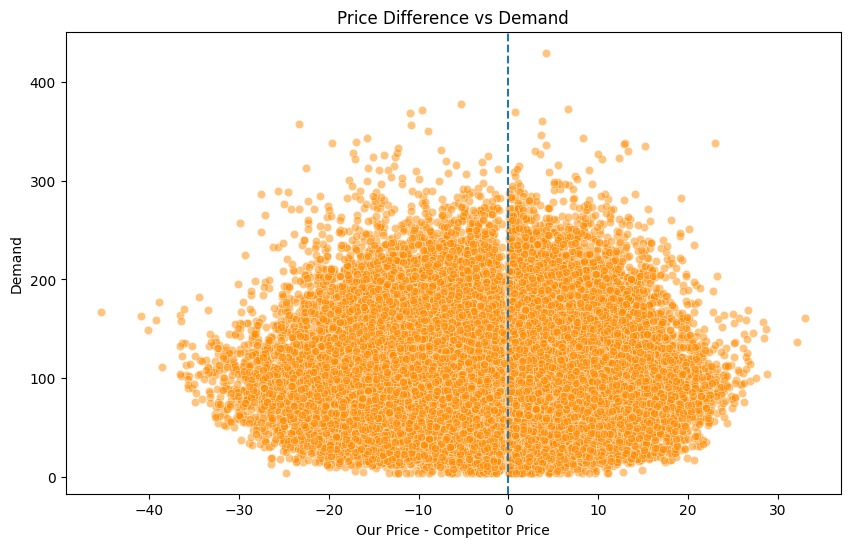

In [41]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Price_Difference",
    y="Demand",
    alpha=0.5,color="darkorange"
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.title("Price Difference vs Demand")
plt.xlabel("Our Price - Competitor Price")
plt.ylabel("Demand")

plt.show()

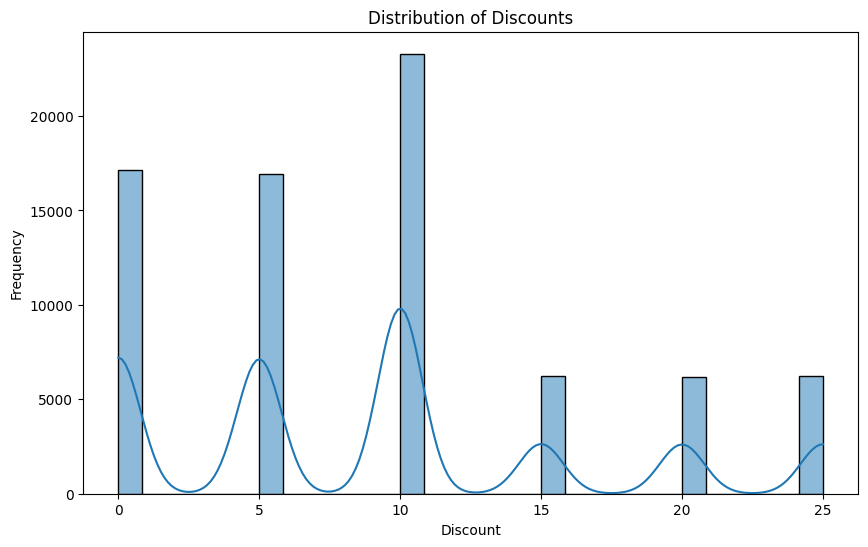

In [43]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Discount",
    bins=30,
    kde=True
)
plt.title("Distribution of Discounts")
plt.xlabel("Discount")
plt.ylabel("Frequency")

plt.show()

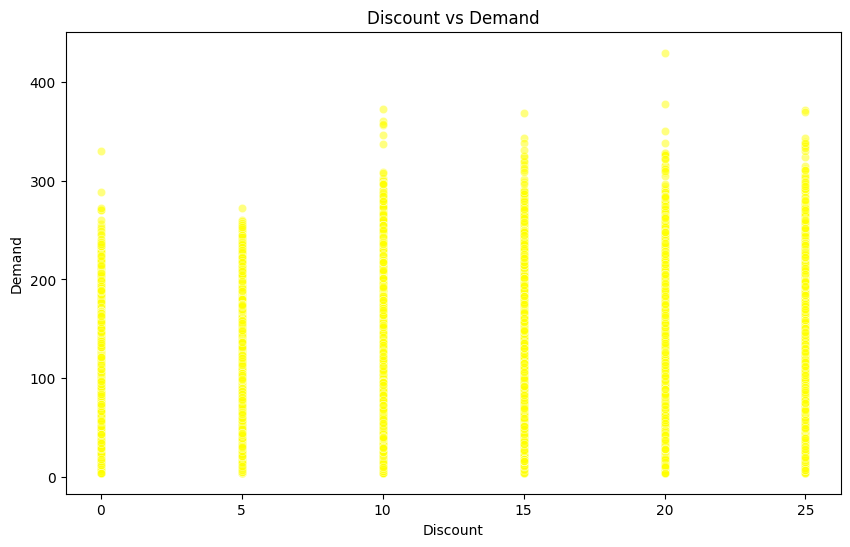

In [46]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Demand",
    alpha=0.5,color="yellow"
)

plt.title("Discount vs Demand")
plt.xlabel("Discount")
plt.ylabel("Demand")
plt.show()

In [47]:
df["Promotion"].value_counts()

Promotion
0    51000
1    25000
Name: count, dtype: int64

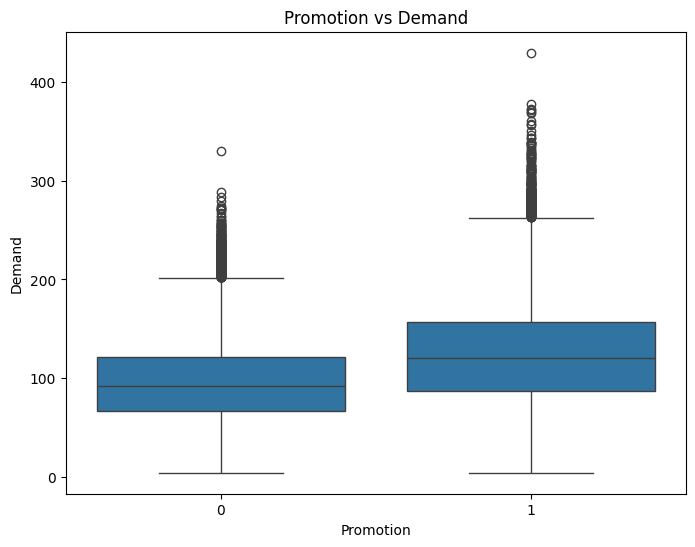

In [48]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="Promotion",
    y="Demand"
)

plt.title("Promotion vs Demand")
plt.xlabel("Promotion")
plt.ylabel("Demand")

plt.show()

In [49]:
df.groupby("Promotion")["Demand"].mean()

Promotion
0     95.026843
1    123.269400
Name: Demand, dtype: float64

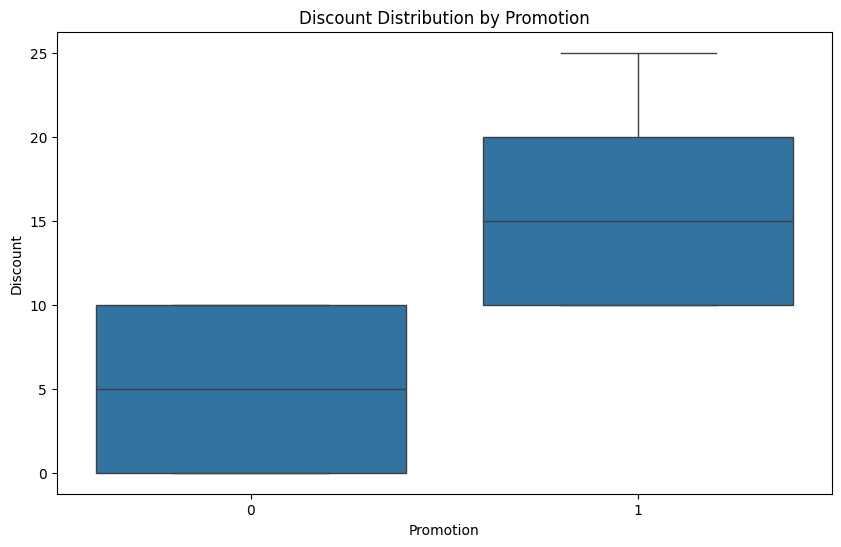

In [51]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Promotion",
    y="Discount")

plt.title("Discount Distribution by Promotion")
plt.xlabel("Promotion")
plt.ylabel("Discount")

plt.show()

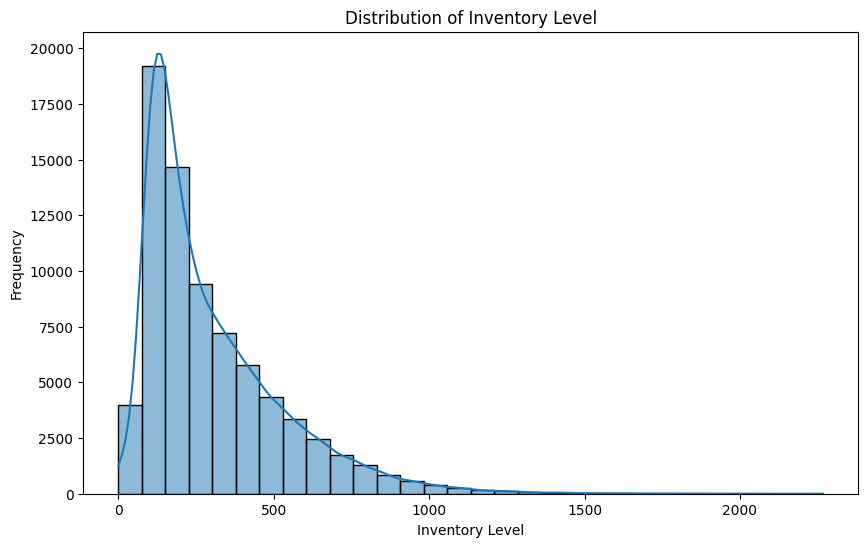

In [52]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Inventory Level",
    bins=30,
    kde=True
)

plt.title("Distribution of Inventory Level")
plt.xlabel("Inventory Level")
plt.ylabel("Frequency")

plt.show()

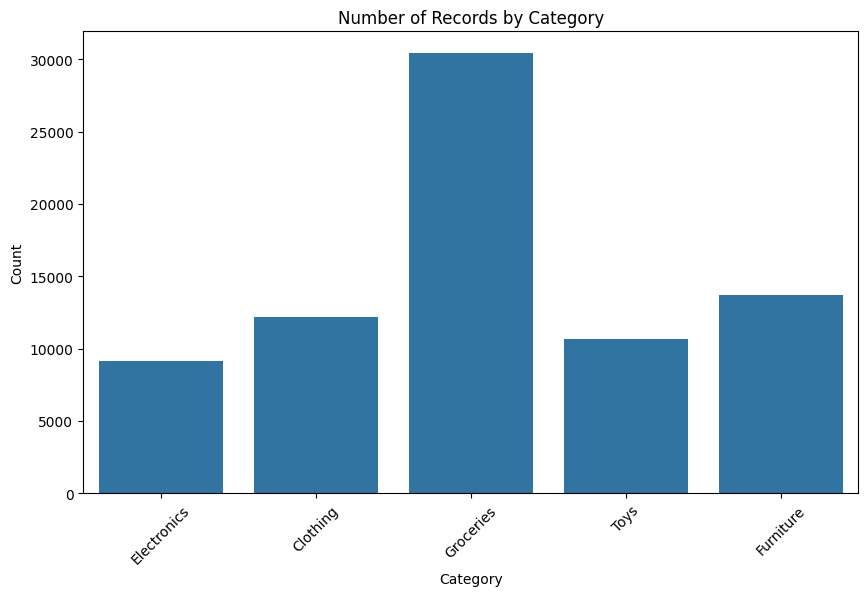

In [53]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Category"
)

plt.title("Number of Records by Category")
plt.xlabel("Category")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()

In [54]:
category_demand = (
    df.groupby("Category")["Demand"]
    .mean()
    .sort_values(ascending=False)
)

category_demand

Category
Groceries      120.976447
Clothing       112.619737
Electronics     97.482018
Toys            92.606955
Furniture       73.581140
Name: Demand, dtype: float64

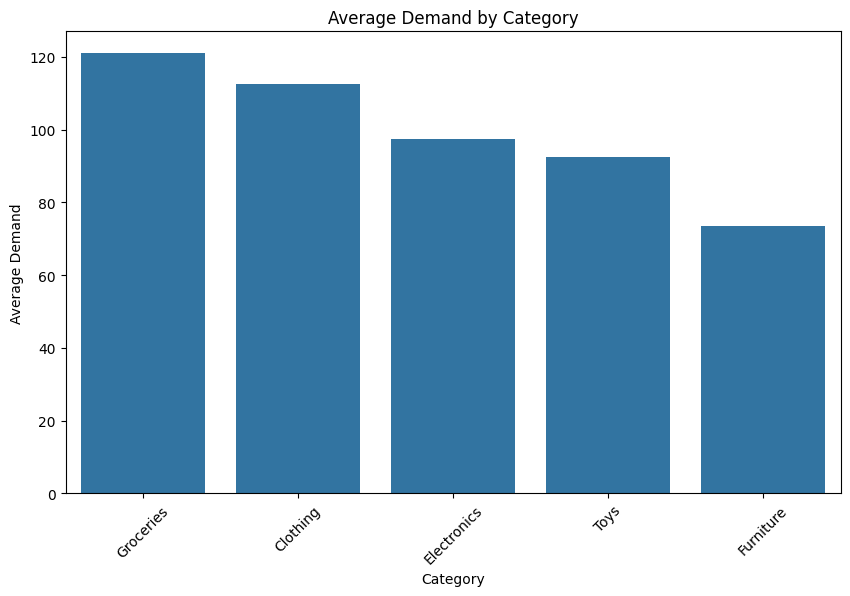

In [55]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_demand.index,
    y=category_demand.values
)

plt.title("Average Demand by Category")
plt.xlabel("Category")
plt.ylabel("Average Demand")

plt.xticks(rotation=45)

plt.show()

In [56]:
region_demand = (
    df.groupby("Region")["Demand"]
    .mean()
    .sort_values(ascending=False)
)

region_demand

Region
South    106.938882
East     106.468684
North    103.771645
West     100.634934
Name: Demand, dtype: float64

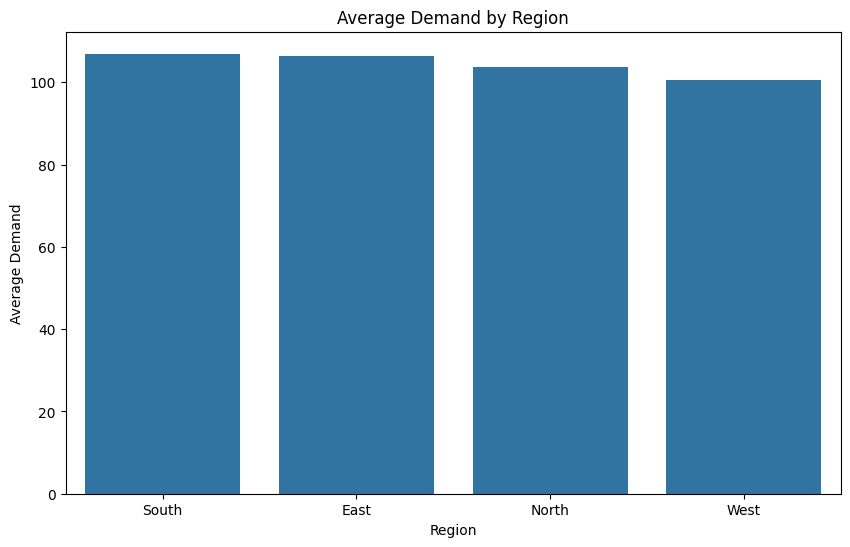

In [57]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=region_demand.index,
    y=region_demand.values
)

plt.title("Average Demand by Region")
plt.xlabel("Region")
plt.ylabel("Average Demand")

plt.show()

In [58]:
season_demand = (
    df.groupby("Seasonality")["Demand"]
    .mean()
    .sort_values(ascending=False)
)

season_demand

Seasonality
Summer    112.855380
Autumn    103.422967
Winter    103.406190
Spring     97.703098
Name: Demand, dtype: float64

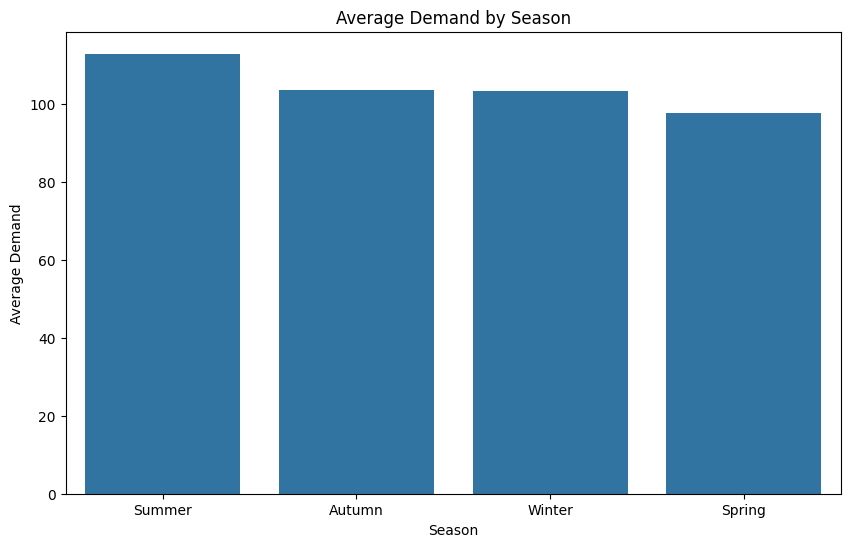

In [59]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=season_demand.index,
    y=season_demand.values
)

plt.title("Average Demand by Season")
plt.xlabel("Season")
plt.ylabel("Average Demand")

plt.show()

In [60]:
weather_demand = (
    df.groupby("Weather Condition")["Demand"]
    .mean()
    .sort_values(ascending=False)
)

weather_demand

Weather Condition
Sunny     115.167189
Cloudy    105.404064
Rainy      95.106743
Snowy      94.045789
Name: Demand, dtype: float64

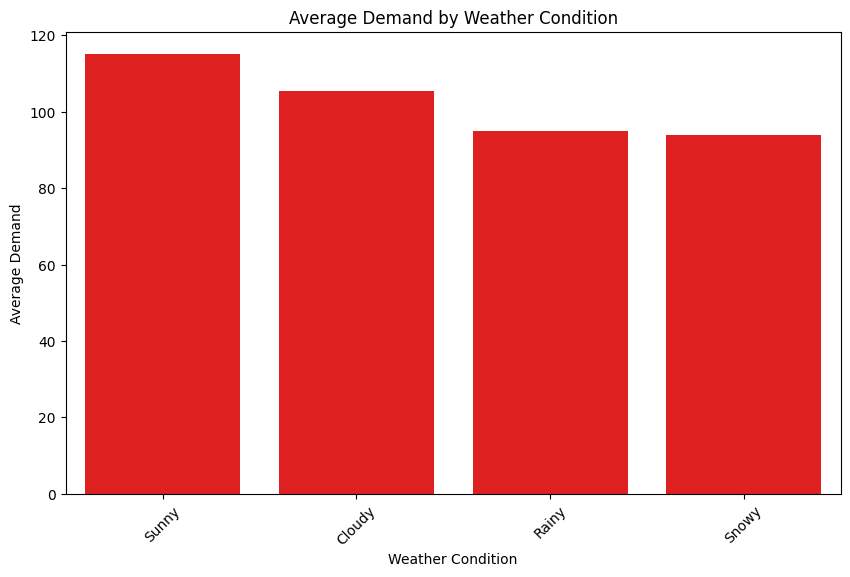

In [62]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=weather_demand.index,
    y=weather_demand.values,color='red'
)

plt.title("Average Demand by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Demand")

plt.xticks(rotation=45)

plt.show()

In [63]:
df["Date"] = pd.to_datetime(df["Date"])

In [65]:
monthly_demand = (
    df.groupby(df["Date"].dt.to_period("M"))["Demand"]
    .mean())

monthly_demand

Date
2022-01    110.175484
2022-02    114.243929
2022-03    113.926774
2022-04    101.692000
2022-05     77.132903
2022-06    115.241667
2022-07     83.785806
2022-08    119.495806
2022-09    108.088000
2022-10    106.408065
2022-11    108.135333
2022-12    112.719677
2023-01    109.633871
2023-02     71.521071
2023-03    113.300968
2023-04     83.941333
2023-05     95.909355
2023-06    119.450333
2023-07    119.337419
2023-08    120.110968
2023-09    106.775000
2023-10     84.706452
2023-11    106.949333
2023-12    105.286774
2024-01     98.053000
Freq: M, Name: Demand, dtype: float64

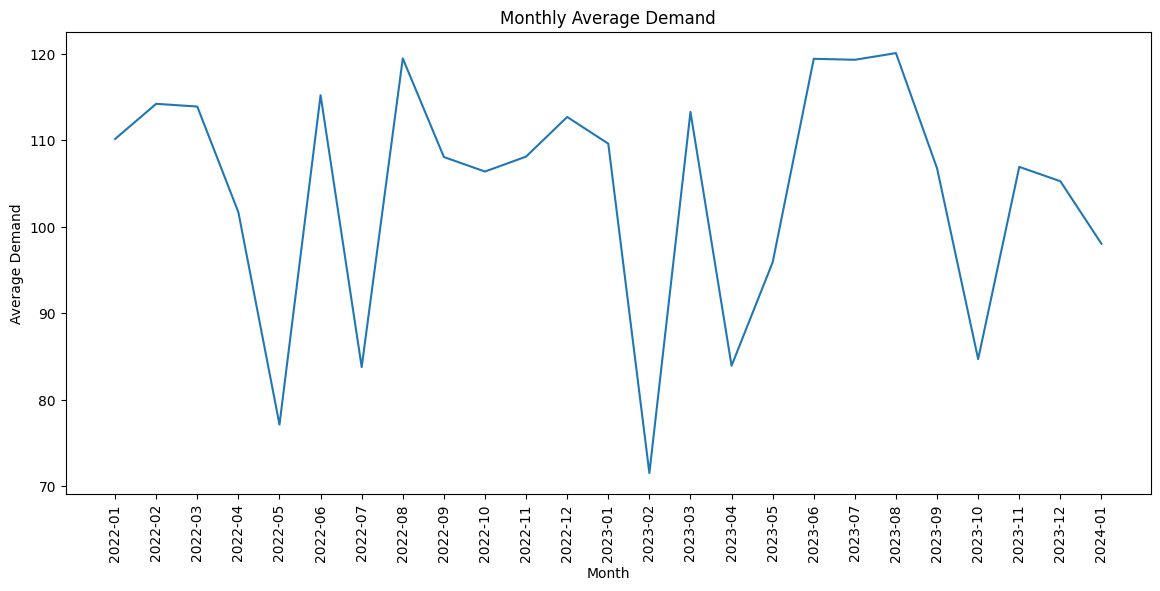

In [66]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_demand.index.astype(str),
    monthly_demand.values
)

plt.title("Monthly Average Demand")
plt.xlabel("Month")
plt.ylabel("Average Demand")

plt.xticks(rotation=90)

plt.show()

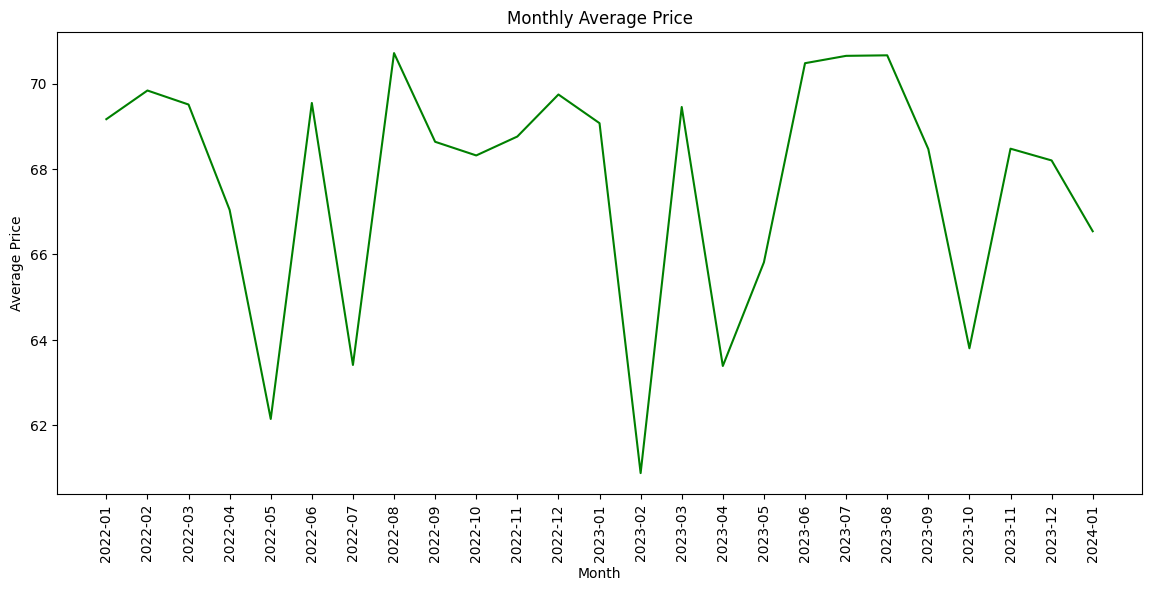

In [68]:
monthly_price = (
    df.groupby(df["Date"].dt.to_period("M"))["Price"]
    .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_price.index.astype(str),
    monthly_price.values,color='green'
)

plt.title("Monthly Average Price")
plt.xlabel("Month")
plt.ylabel("Average Price")

plt.xticks(rotation=90)

plt.show()

In [69]:
numeric_columns = df.select_dtypes(include=np.number)

correlation_matrix = numeric_columns.corr()

correlation_matrix

,Inventory Level,Units Sold,Units Ordered,Price,Discount,Promotion,Competitor Pricing,Epidemic,Demand,Price_Difference
Inventory Level,1.000000,0.234590,-0.034698,-0.036673,-0.000678,-0.006082,-0.034754,-0.097550,0.126618,-0.002401
Units Sold,0.234590,1.000000,0.433943,-0.014506,0.183523,0.227062,-0.013989,-0.317855,0.833421,0.000174
Units Ordered,-0.034698,0.433943,1.000000,0.044980,0.172972,0.214743,0.045235,-0.100546,0.511963,-0.009174
Price,-0.036673,-0.014506,0.044980,1.000000,-0.094136,-0.043190,0.976648,-0.089658,-0.023461,-0.069158
Discount,-0.000678,0.183523,0.172972,-0.094136,1.000000,0.784039,-0.092066,-0.003885,0.224723,0.007105
Promotion,-0.006082,0.227062,0.214743,-0.043190,0.784039,1.000000,-0.041385,0.000700,0.282537,-0.000713
Competitor Pricing,-0.034754,-0.013989,0.045235,0.976648,-0.092066,-0.041385,1.000000,-0.089466,-0.023036,-0.281873
Epidemic,-0.097550,-0.317855,-0.100546,-0.089658,-0.003885,0.000700,-0.089466,1.000000,-0.363661,0.015032
Demand,0.126618,0.833421,0.511963,-0.023461,0.224723,0.282537,-0.023036,-0.363661,1.000000,0.002196
Price_Difference,-0.002401,0.000174,-0.009174,-0.069158,0.007105,-0.000713,-0.281873,0.015032,0.002196,1.000000


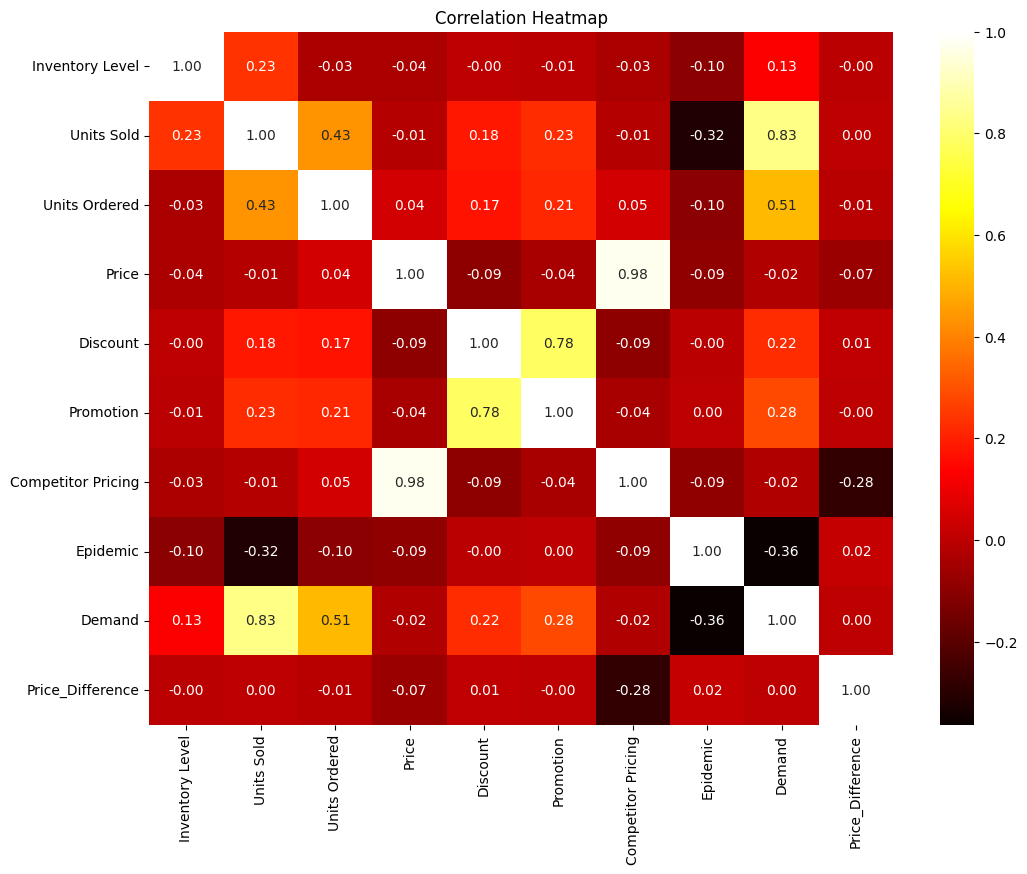

In [73]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="hot"
)

plt.title("Correlation Heatmap")

plt.show()

In [74]:
demand_correlation = (
    correlation_matrix["Demand"]
    .sort_values(ascending=False)
)

demand_correlation

Demand                1.000000
Units Sold            0.833421
Units Ordered         0.511963
Promotion             0.282537
Discount              0.224723
Inventory Level       0.126618
Price_Difference      0.002196
Competitor Pricing   -0.023036
Price                -0.023461
Epidemic             -0.363661
Name: Demand, dtype: float64

In [75]:
price_demand_by_category = (
    df.groupby("Category")
      .apply(
          lambda x: x["Price"].corr(x["Demand"]),
          include_groups=False
      )
)

price_demand_by_category.sort_values()

Category
Groceries      0.216982
Clothing       0.233628
Electronics    0.371118
Toys           0.436500
Furniture      0.444522
dtype: float64

In [76]:
df["Revenue"] = df["Price"] * df["Units Sold"]

In [77]:
df["Revenue"].describe()

count    76000.000000
mean      5990.790717
std       4756.214481
min          0.000000
25%       2426.595000
50%       4789.285000
75%       8349.327500
max      69859.740000
Name: Revenue, dtype: float64

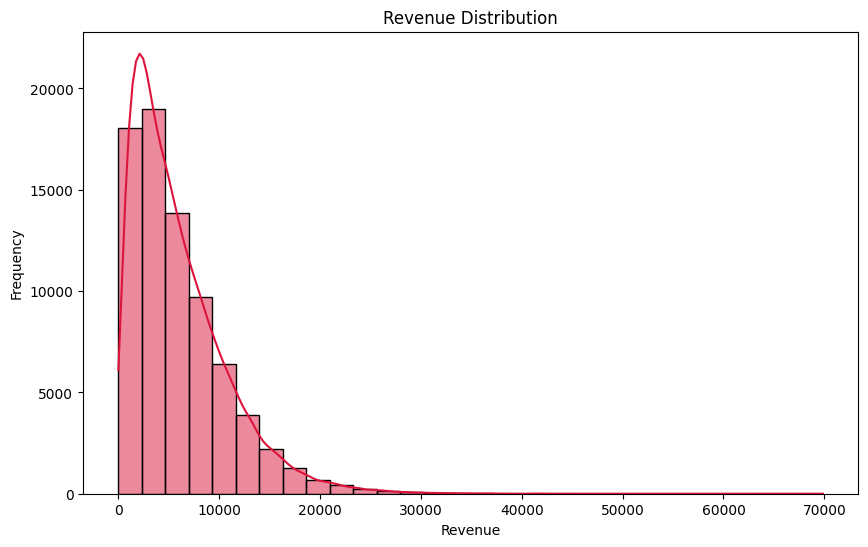

In [82]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Revenue",
    bins=30,
    kde=True,color='crimson')

plt.title("Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Frequency")

plt.show()

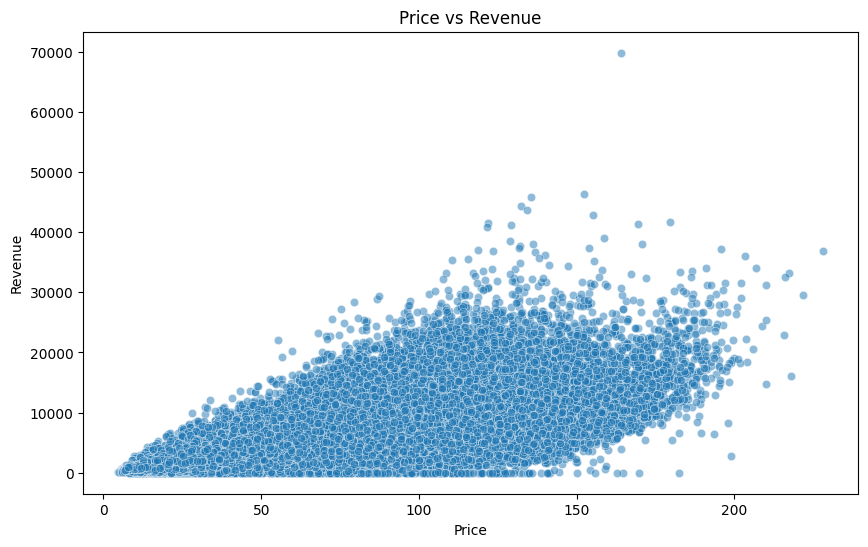

In [83]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Price",
    y="Revenue",
    alpha=0.5
)

plt.title("Price vs Revenue")
plt.xlabel("Price")
plt.ylabel("Revenue")

plt.show()

In [84]:
top_products = (
    df.groupby("Product ID")["Demand"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Product ID
P0009    118.506316
P0013    116.025000
P0004    115.396053
P0007    115.023421
P0002    112.066579
P0010    111.069474
P0001    109.591316
P0006    107.722368
P0005    107.520526
P0008    104.352105
Name: Demand, dtype: float64

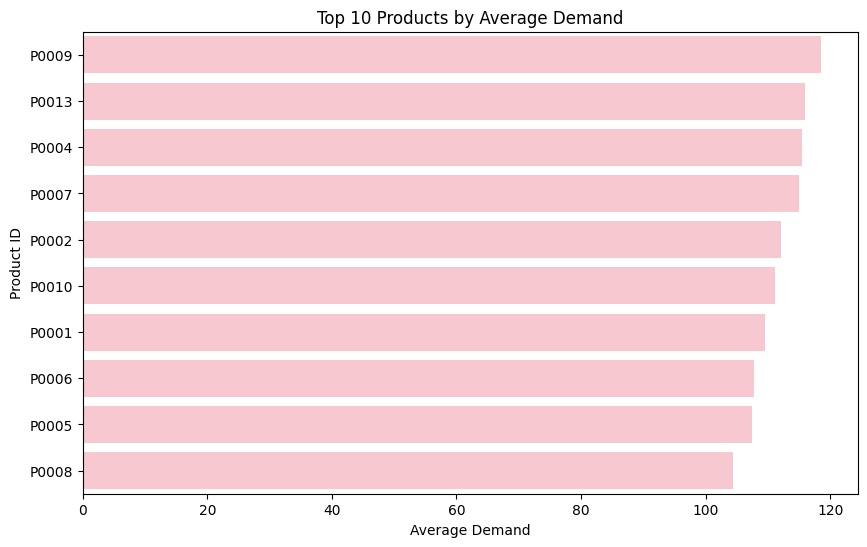

In [88]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index,color='pink'
)

plt.title("Top 10 Products by Average Demand")
plt.xlabel("Average Demand")
plt.ylabel("Product ID")

plt.show()